# Lab 28-06 · Flags, False Alarms and Funnels

Companion to [chapter 28-06](../../chapters/28-06-red-and-green-flags.md). Every part asks you to **predict first**, then run. All rates are the chapter's assumptions.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
sys.path.insert(0, '.')
import flagmodel as fm

## Part 1 · False alarms

**Predict:** the chance that a healthy company shows at least one of 50 flags at 3% each.

78.2%


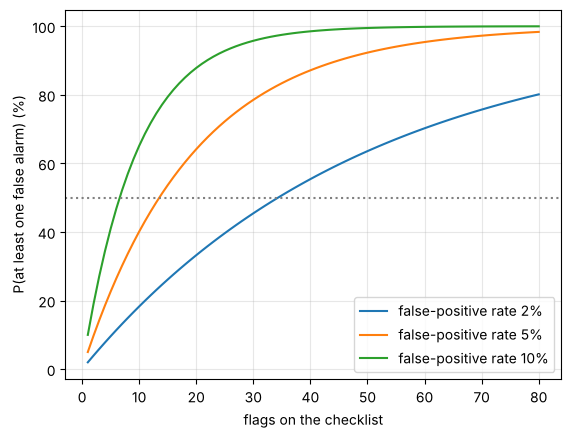

In [2]:
print(f"{100*fm.false_alarm(50, 0.03):.1f}%")
n = np.arange(1, 81)
for f in (0.02, 0.05, 0.10):
    plt.plot(n, [100*fm.false_alarm(k, f) for k in n], label=f'false-positive rate {int(100*f)}%')
plt.axhline(50, color='grey', ls=':')
plt.xlabel('flags on the checklist'); plt.ylabel('P(at least one false alarm) (%)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 2 · Count thresholds

**Predict:** the smallest threshold with a likelihood ratio above 100 (25 flags; 4% healthy, 30% troubled).

K >= 1: sensitivity 100.0%, false-positive 63.9603%, ratio        1.6
K >= 2: sensitivity  99.8%, false-positive 26.4190%, ratio        3.8
K >= 3: sensitivity  99.1%, false-positive  7.6483%, ratio       13.0
K >= 4: sensitivity  96.7%, false-positive  1.6522%, ratio       58.5
K >= 5: sensitivity  91.0%, false-positive  0.2780%, ratio      327.1
K >= 6: sensitivity  80.7%, false-positive  0.0376%, ratio     2147.3
K >= 7: sensitivity  65.9%, false-positive  0.0042%, ratio    15845.0
K >= 8: sensitivity  48.8%, false-positive  0.0004%, ratio   127137.0
smallest threshold above 100: 5 (sensitivity 91.0%)


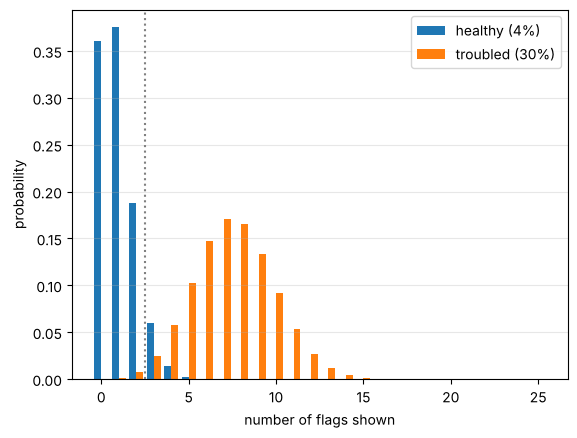

In [3]:
rows = fm.threshold_table(25, 0.04, 0.30, 8)
for k, se, fp, lr in rows:
    print(f"K >= {k}: sensitivity {100*se:5.1f}%, false-positive {100*fp:7.4f}%, ratio {lr:10.1f}")
best = next(r for r in rows if r[3] > 100)
print(f"smallest threshold above 100: {best[0]} (sensitivity {100*best[1]:.1f}%)")
k = np.arange(0, 26)
plt.bar(k - 0.2, stats.binom.pmf(k, 25, 0.04), width=0.4, label='healthy (4%)')
plt.bar(k + 0.2, stats.binom.pmf(k, 25, 0.30), width=0.4, label='troubled (30%)')
plt.axvline(2.5, color='grey', ls=':')
plt.xlabel('number of flags shown'); plt.ylabel('probability'); plt.legend(); plt.grid(True, axis='y', alpha=0.3); plt.show()

## Part 3 · Key-person risk over time

**Predict:** the chance of losing at least one of five key engineers within three years at 12% a year.

85.3%


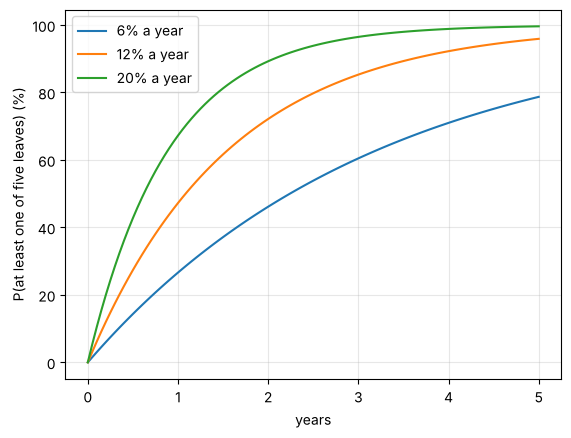

In [4]:
print(f"{100*fm.key_person_loss(5, 0.12, 3):.1f}%")
t = np.linspace(0, 5, 101)
for q in (0.06, 0.12, 0.20):
    plt.plot(t, [100*fm.key_person_loss(5, q, x) for x in t], label=f'{int(100*q)}% a year')
plt.xlabel('years'); plt.ylabel('P(at least one of five leaves) (%)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 4 · The funnel

Example 28-06.5: 40 wins at $3M each, revenue in years 2 to 4.

**Predict:** the risk-adjusted value at 40% conversion (12% discount rate).

$34.3M


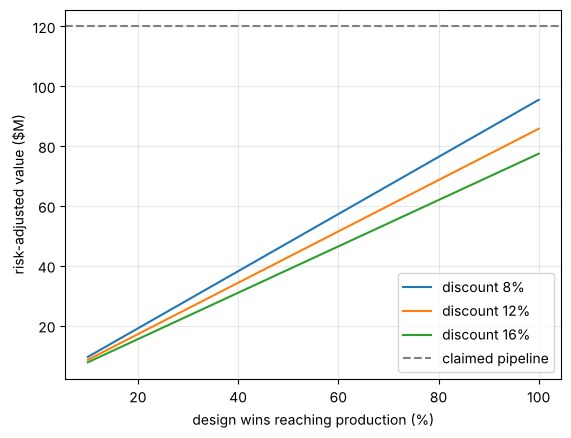

In [5]:
print(f"${fm.funnel_value(40, 0.4, 3, 2, 3, 0.12):.1f}M")
p = np.linspace(0.1, 1.0, 91)
for r in (0.08, 0.12, 0.16):
    plt.plot(100*p, [fm.funnel_value(40, x, 3, 2, 3, r) for x in p], label=f'discount {int(100*r)}%')
plt.axhline(120, color='grey', ls='--', label='claimed pipeline')
plt.xlabel('design wins reaching production (%)'); plt.ylabel('risk-adjusted value ($M)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()